# 20 Kemiripan Teks dan Parafrase

Mengukur seberapa mirip dua teks. Contoh: STS Benchmark terjemahan Indonesia dengan skor 0 sampai 5.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Mengukur kemiripan dua teks |
| **Unit prediksi** | Satu pasangan teks mendapat skor 0 sampai 5 |
| **Metrik** | Pearson dan Spearman |
| **Masalah terbesar** | Sumber data holdout berbeda (`answer-answer` hanya ada di holdout), jadi OOF terlalu optimistis: cross-encoder OOF 0,8319 turun ke holdout 0,7669. |
| **Data contoh** | STSB versi Indonesia, 1.500 latih, 1.379 holdout |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** data berisi pasangan teks dengan skor kemiripan, atau soal meminta deteksi parafrase. Metriknya
biasanya Pearson, Spearman, atau F1. Kalau labelnya entailment, pakai folder `21`.

**Yang perlu diganti kalau datanya beda:**
- `load_data`, kolom `text_1`, `text_2`, `score`.
- `PARAPHRASE_MIN_SCORE`, batas skor yang dianggap parafrase.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya fitur TF-IDF, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
PARAPHRASE_MIN_SCORE = 4.0

SETTINGS = {
    "cepat": {"folds": 3, "epochs": 3, "model_runs": [("indobert", SEED)]},
    "penuh": {"folds": 5, "epochs": 5, "model_runs": [("indobert", SEED), ("indobert", SEED + 1)]},
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'folds': 5, 'epochs': 5, 'model_runs': [('indobert', 42), ('indobert', 43)]}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Embedding teks.** Kalau pretrained boleh dipakai, teks diubah dengan multilingual-e5. Kalau
tidak boleh, `USE_PRETRAINED=False` memakai TF-IDF + SVD sebagai gantinya.

In [6]:
from sklearn.decomposition import TruncatedSVD  # noqa: E402
from sklearn.feature_extraction.text import TfidfVectorizer as _Tfidf  # noqa: E402
from sklearn.preprocessing import normalize as _l2  # noqa: E402
from transformers import AutoModel, AutoTokenizer  # noqa: E402


def tfidf_svd_embed(texts: list[str], dim: int = 256) -> np.ndarray:
    """Embedding tanpa pretrained: TF-IDF kata + SVD."""
    matrix = _Tfidf(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    dim = min(dim, matrix.shape[1] - 1, matrix.shape[0] - 1)
    return _l2(TruncatedSVD(dim, random_state=SEED).fit_transform(matrix))


@torch.inference_mode()
def e5_embed(texts: list[str], prefix: str = "query: ", batch_size: int = 64) -> np.ndarray:
    """Mean pooling multilingual-e5, hasil dinormalisasi L2."""
    tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR / "e5")
    model = AutoModel.from_pretrained(MODEL_DIR / "e5").to(DEVICE).eval().half()
    order = np.argsort([len(t) for t in texts])
    chunks = []
    for start in range(0, len(texts), batch_size):
        batch = [prefix + texts[i] for i in order[start : start + batch_size]]
        tokens = tokenizer(
            batch, padding=True, truncation=True, max_length=128, return_tensors="pt"
        ).to(DEVICE)
        hidden = model(**tokens).last_hidden_state
        mask = tokens["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(1) / mask.sum(1)
        chunks.append(torch.nn.functional.normalize(pooled, dim=1).float().cpu().numpy())
    del model
    torch.cuda.empty_cache()
    vectors = np.empty((len(texts), chunks[0].shape[1]), dtype=np.float32)
    vectors[order] = np.vstack(chunks)
    return vectors


def embed_texts(texts: list[str]) -> np.ndarray:
    """Pilih embedding sesuai USE_PRETRAINED."""
    return e5_embed(texts) if USE_PRETRAINED else tfidf_svd_embed(texts)

**Training transformer.** Satu fungsi untuk klasifikasi (`problem="ce"`), multi-label (`"bce"`),
dan regresi (`"mse"`). Loop-nya ditulis sendiri supaya mudah dibaca dan outputnya bersih.

In [7]:
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402
from transformers import (  # noqa: E402
    AutoModelForSequenceClassification,
    AutoTokenizer as _SeqTokenizer,
    get_linear_schedule_with_warmup,
)


def _encode(tokenizer, texts, pairs, max_len):
    args = (list(texts), list(pairs)) if pairs is not None else (list(texts),)
    tokens = tokenizer(
        *args, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt"
    )
    return tokens["input_ids"], tokens["attention_mask"]


def _loss_fn(problem, weights):
    if problem == "ce":
        return torch.nn.CrossEntropyLoss(weight=weights)
    # untuk multi-label, class_weights berperan sebagai pos_weight per label
    return (
        torch.nn.BCEWithLogitsLoss(pos_weight=weights) if problem == "bce" else torch.nn.MSELoss()
    )


def _to_output(logits, problem):
    if problem == "ce":
        return torch.softmax(logits.float(), dim=1)
    if problem == "bce":
        return torch.sigmoid(logits.float())
    return logits.float().squeeze(-1)


@torch.inference_mode()
def _predict(model, ids, mask, problem, batch_size):
    model.eval()
    chunks = []
    for start in range(0, len(ids), batch_size):
        batch_ids = ids[start : start + batch_size].to(DEVICE)
        batch_mask = mask[start : start + batch_size].to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            logits = model(input_ids=batch_ids, attention_mask=batch_mask).logits
        chunks.append(_to_output(logits, problem).cpu())
    return torch.cat(chunks).numpy()


def train_predict(
    model_name,
    train_texts,
    train_y,
    predict_sets,
    problem="ce",
    num_labels=None,
    class_weights=None,
    train_pairs=None,
    epochs=3,
    lr=2e-5,
    batch_size=32,
    max_len=128,
    seed=42,
):
    """Latih satu model, lalu kembalikan prediksi untuk tiap set di predict_sets.

    predict_sets: daftar teks, atau daftar pasangan (teks, teks_pair) untuk tugas dua teks.
    """
    seed_everything(seed)
    tokenizer = _SeqTokenizer.from_pretrained(MODEL_DIR / model_name)
    num_labels = num_labels or (int(np.max(train_y)) + 1 if problem == "ce" else 1)
    if problem == "bce":
        num_labels = np.asarray(train_y).shape[1]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_DIR / model_name, num_labels=num_labels, ignore_mismatched_sizes=True
    ).to(DEVICE)

    ids, mask = _encode(tokenizer, train_texts, train_pairs, max_len)
    target = torch.tensor(np.asarray(train_y), dtype=torch.long if problem == "ce" else torch.float)
    if problem == "mse":
        target = target.view(-1, 1)
    loader = DataLoader(
        TensorDataset(ids, mask, target),
        batch_size=batch_size,
        shuffle=True,
        drop_last=len(ids) > batch_size,
    )
    weights = (
        None if class_weights is None else torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
    )
    loss_fn = _loss_fn(problem, weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = max(1, epochs * len(loader))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")

    model.train()
    for _ in range(epochs):
        for batch_ids, batch_mask, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits = model(
                    input_ids=batch_ids.to(DEVICE), attention_mask=batch_mask.to(DEVICE)
                ).logits
                loss = loss_fn(logits, batch_y.to(DEVICE))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

    outputs = []
    for item in predict_sets:
        texts, pairs = item if isinstance(item, tuple) else (item, None)
        pred_ids, pred_mask = _encode(tokenizer, texts, pairs, max_len)
        outputs.append(_predict(model, pred_ids, pred_mask, problem, batch_size * 2))
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return outputs

## 4. EDA

Muat data. Split validation dipakai untuk latih dengan cross-validation, dan split test sebagai holdout.

In [8]:
from scipy.stats import pearsonr, spearmanr  # noqa: E402
from sklearn.isotonic import IsotonicRegression  # noqa: E402
from sklearn.linear_model import Ridge  # noqa: E402
from sklearn.metrics import f1_score  # noqa: E402
from sklearn.model_selection import GroupKFold  # noqa: E402


def load_data(split: str) -> pd.DataFrame:
    frame = pd.read_parquet(EXTRA_DATA_DIR / "stsb_id" / f"{split}.parquet")
    frame["score"] = pd.to_numeric(frame["correlation"], errors="coerce")
    return frame.dropna(subset=["text_1", "text_2", "score"]).head(N_ROWS).reset_index(drop=True)


train, test = load_data("validation"), load_data("test")
print(f"latih={len(train)} | holdout={len(test)}")
print("sumber data:", train["data"].value_counts().head(5).to_dict())
print("sumber holdout:", test["data"].value_counts().head(5).to_dict())
train[["text_1", "text_2", "score"]].head(3)

latih=1500 | holdout=1379
sumber data: {'answers-forums': 375, 'MSRvid': 250, 'images': 250, 'MSRpar': 250, 'headlines': 250}
sumber holdout: {'answer-answer': 254, 'MSRvid': 250, 'images': 250, 'MSRpar': 250, 'headlines': 250}


,text_1,text_2,score
0,Seorang pria bertopi keras sedang menari.,Seorang pria bertopi keras sedang menari.,5.00
1,Seorang anak kecil sedang menunggang kuda.,Seorang anak sedang menunggang kuda.,4.75
2,Seorang pria memberi makan tikus ke ular.,Pria itu memberi makan tikus ke ular.,5.00


Sebaran skor dan pergeseran antara latih dan holdout.

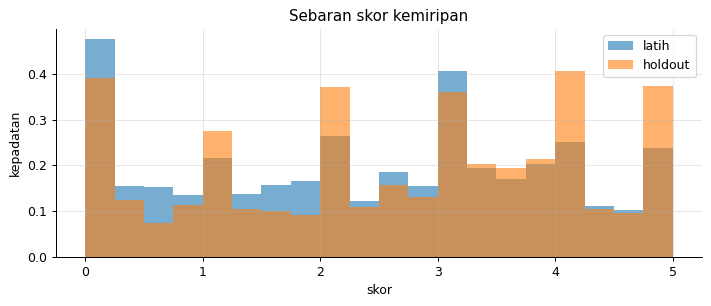

AUC adversarial: 0.508 | parafrase latih: 17.6%


In [9]:
fig, ax = plt.subplots()
ax.hist(train["score"], bins=20, alpha=0.6, label="latih", density=True)
ax.hist(test["score"], bins=20, alpha=0.6, label="holdout", density=True)
ax.set(title="Sebaran skor kemiripan", xlabel="skor", ylabel="kepadatan")
ax.legend()
plt.tight_layout()
plt.show()
shift_auc = adversarial_auc(
    (train["text_1"] + " " + train["text_2"]).tolist(),
    (test["text_1"] + " " + test["text_2"]).tolist(),
)
print(
    f"AUC adversarial: {shift_auc:.3f} | parafrase latih: {(train['score'] >= PARAPHRASE_MIN_SCORE).mean():.1%}"
)

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Satu teks muncul di banyak pasangan | Grup validasi dari kedua teks |
| Skor berbeda jauh antar sumber | Laporkan Pearson per sumber |
| AUC adversarial 0,508 | Dari isi teks tidak ada shift yang kuat, tapi skor per sumber tetap berbeda |

## 5. Preprocessing

Pembersihan ringan. Satu teks bisa muncul di banyak pasangan, jadi grup validasi dibuat dari kedua teks, supaya
teks yang sama tidak lintas fold.

In [10]:
for frame in (train, test):
    frame["a"], frame["b"] = frame["text_1"].map(clean_text), frame["text_2"].map(clean_text)
all_text = pd.concat([train["a"], train["b"]]).unique()
text_to_id = {t: i for i, t in enumerate(all_text)}
parent = list(range(len(all_text)))


def find_root(i: int) -> int:
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


for a, b in zip(train["a"], train["b"]):
    parent[find_root(text_to_id[a])] = find_root(text_to_id[b])
train["group"] = [find_root(text_to_id[a]) for a in train["a"]]
y, y_holdout = train["score"].to_numpy(), test["score"].to_numpy()
print(f"grup: {train['group'].nunique()} dari {len(train)} pasangan")

grup: 1399 dari 1500 pasangan


## 6. Validasi

`GroupKFold` berdasarkan grup teks. Metrik utama Pearson dan Spearman. F1 parafrase dihitung setelah skor diberi
threshold.

In [11]:
def pearson(y_true, y_pred) -> float:
    return float(pearsonr(y_true, y_pred)[0])


assert abs(pearson([1, 2, 3], [2, 4, 6]) - 1.0) < 1e-9
folds = np.zeros(len(train), dtype=int)
for fold, (_, val_idx) in enumerate(GroupKFold(SETTINGS["folds"]).split(train, y, train["group"])):
    folds[val_idx] = fold
results: list[dict] = []


def record(name: str, oof, holdout) -> None:
    results.append(
        {
            "model": name,
            "pearson_oof": round(pearson(y, oof), 4),
            "spearman_oof": round(float(spearmanr(y, oof)[0]), 4),
            "pearson_holdout": round(pearson(y_holdout, holdout), 4),
            "spearman_holdout": round(float(spearmanr(y_holdout, holdout)[0]), 4),
        }
    )
    print(results[-1])

## 7. Baseline

Cosine TF-IDF, tanpa pelatihan. Lalu Ridge dari fitur tumpang tindih kata.

In [12]:
pair_vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(
    pd.concat([train["a"], train["b"]])
)


def cosine_tfidf(frame: pd.DataFrame) -> np.ndarray:
    left, right = pair_vectorizer.transform(frame["a"]), pair_vectorizer.transform(frame["b"])
    return np.asarray(left.multiply(right).sum(1)).ravel()


def pair_features(frame: pd.DataFrame) -> np.ndarray:
    rows = []
    for a, b, cosine in zip(frame["a"], frame["b"], cosine_tfidf(frame)):
        set_a, set_b = set(a.split()), set(b.split())
        rows.append(
            [
                cosine,
                len(set_a & set_b) / max(len(set_a | set_b), 1),
                abs(len(set_a) - len(set_b)) / max(len(set_a | set_b), 1),
            ]
        )
    return np.array(rows)


x_train, x_test = pair_features(train), pair_features(test)
record("cosine_tfidf", x_train[:, 0], x_test[:, 0])
oof_ridge, hold_ridge = np.zeros(len(y)), np.zeros(len(y_holdout))
for fold in range(SETTINGS["folds"]):
    fit, val = folds != fold, folds == fold
    model = Ridge(alpha=1.0).fit(x_train[fit], y[fit])
    oof_ridge[val] = model.predict(x_train[val])
    hold_ridge += model.predict(x_test) / SETTINGS["folds"]
record("ridge_fitur_kata", oof_ridge, hold_ridge)

{'model': 'cosine_tfidf', 'pearson_oof': 0.6978, 'spearman_oof': 0.731, 'pearson_holdout': 0.6111, 'spearman_holdout': 0.6031}
{'model': 'ridge_fitur_kata', 'pearson_oof': 0.6963, 'spearman_oof': 0.7252, 'pearson_holdout': 0.6108, 'spearman_holdout': 0.6038}


## 8. Model Utama

**Bi-encoder e5:** cosine embedding, tanpa pelatihan, jadi bisa dipakai kalau tidak ada label.
**Cross-encoder IndoBERT:** kedua teks masuk bersamaan dan dilatih dengan loss MSE. Biasanya lebih akurat tapi
butuh label.

In [13]:
with stage("biencoder"):
    if USE_PRETRAINED:
        cos_train = np.sum(e5_embed(train["a"].tolist()) * e5_embed(train["b"].tolist()), axis=1)
        cos_test = np.sum(e5_embed(test["a"].tolist()) * e5_embed(test["b"].tolist()), axis=1)
        record("biencoder_e5", cos_train, cos_test)
    else:
        cos_train, cos_test = x_train[:, 0], x_test[:, 0]

mean_y, std_y = y.mean(), y.std()
oof_cross, hold_cross = np.zeros(len(y)), np.zeros(len(y_holdout))
with stage("cross_encoder"):
    if USE_PRETRAINED:
        for model_name, seed in SETTINGS["model_runs"]:
            for fold in range(SETTINGS["folds"]):
                fit, val = folds != fold, folds == fold
                pred_val, pred_hold = train_predict(
                    model_name,
                    train.loc[fit, "a"].tolist(),
                    (y[fit] - mean_y) / std_y,
                    [
                        (train.loc[val, "a"].tolist(), train.loc[val, "b"].tolist()),
                        (test["a"].tolist(), test["b"].tolist()),
                    ],
                    problem="mse",
                    num_labels=1,
                    train_pairs=train.loc[fit, "b"].tolist(),
                    epochs=SETTINGS["epochs"],
                    seed=seed + fold,
                    batch_size=16,
                )
                oof_cross[val] += pred_val * std_y + mean_y
                hold_cross += (pred_hold * std_y + mean_y) / SETTINGS["folds"]
        oof_cross /= len(SETTINGS["model_runs"])
        hold_cross /= len(SETTINGS["model_runs"])
        record("cross_encoder", oof_cross, hold_cross)
    else:
        oof_cross, hold_cross = oof_ridge, hold_ridge

{'model': 'biencoder_e5', 'pearson_oof': 0.6198, 'spearman_oof': 0.6483, 'pearson_holdout': 0.6659, 'spearman_holdout': 0.6824}
[waktu] biencoder: 44 detik


{'model': 'cross_encoder', 'pearson_oof': 0.8319, 'spearman_oof': 0.8267, 'pearson_holdout': 0.7669, 'spearman_holdout': 0.7442}
[waktu] cross_encoder: 575 detik


## 9. Post-processing

Gabungkan bi-encoder dan cross-encoder dengan rata-rata peringkat tanpa bobot. Lalu kalibrasi isotonik supaya
skala skornya kembali ke 0 sampai 5, yang penting kalau metriknya RMSE. Kalibrasi difit di OOF dan di dalam fold.

In [14]:
def to_rank(values: np.ndarray) -> np.ndarray:
    return pd.Series(values).rank(pct=True).to_numpy()


oof_blend = (to_rank(oof_cross) + to_rank(cos_train)) / 2
hold_blend = (to_rank(hold_cross) + to_rank(cos_test)) / 2
record("gabungan_peringkat", oof_blend, hold_blend)

oof_final = np.zeros(len(y))
for fold in range(SETTINGS["folds"]):
    fit, val = folds != fold, folds == fold
    oof_final[val] = (
        IsotonicRegression(out_of_bounds="clip").fit(oof_blend[fit], y[fit]).predict(oof_blend[val])
    )
hold_final = IsotonicRegression(out_of_bounds="clip").fit(oof_blend, y).predict(hold_blend)
record("gabungan_plus_kalibrasi", oof_final, hold_final)

{'model': 'gabungan_peringkat', 'pearson_oof': 0.7985, 'spearman_oof': 0.7961, 'pearson_holdout': 0.7762, 'spearman_holdout': 0.7691}
{'model': 'gabungan_plus_kalibrasi', 'pearson_oof': 0.7939, 'spearman_oof': 0.7848, 'pearson_holdout': 0.7788, 'spearman_holdout': 0.769}


**Deteksi parafrase:** threshold F1 difit nested dari skor OOF.

In [15]:
is_paraphrase, is_paraphrase_holdout = y >= PARAPHRASE_MIN_SCORE, y_holdout >= PARAPHRASE_MIN_SCORE


def best_cut(scores, target) -> float:
    grid = np.quantile(scores, np.linspace(0.3, 0.95, 66))
    return float(
        grid[int(np.argmax([f1_score(target, scores >= c, zero_division=0) for c in grid]))]
    )


nested = np.zeros(len(y), dtype=bool)
for fold in range(SETTINGS["folds"]):
    fit, val = folds != fold, folds == fold
    nested[val] = oof_blend[val] >= best_cut(oof_blend[fit], is_paraphrase[fit])
cut = best_cut(oof_blend, is_paraphrase)
paraphrase_scores = {
    "f1_oof": round(f1_score(is_paraphrase, nested), 4),
    "f1_holdout": round(f1_score(is_paraphrase_holdout, hold_blend >= cut), 4),
}
print("parafrase:", paraphrase_scores)

parafrase: {'f1_oof': 0.5732, 'f1_holdout': 0.5745}


## 10. Post-analysis

**Tabel perbandingan.**

In [16]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,model,pearson_oof,spearman_oof,pearson_holdout,spearman_holdout
0,cosine_tfidf,0.6978,0.7310,0.6111,0.6031
1,ridge_fitur_kata,0.6963,0.7252,0.6108,0.6038
2,biencoder_e5,0.6198,0.6483,0.6659,0.6824
3,cross_encoder,0.8319,0.8267,0.7669,0.7442
4,gabungan_peringkat,0.7985,0.7961,0.7762,0.7691
5,gabungan_plus_kalibrasi,0.7939,0.7848,0.7788,0.7690


**Skor menurut sumber data** pada holdout, karena beda sumber bisa beda kesulitan.

In [17]:
test.assign(pred=hold_final).groupby("data").apply(
    lambda g: pd.Series({"baris": len(g), "pearson": round(pearson(g["score"], g["pred"]), 3)}),
    include_groups=False,
).sort_values("baris", ascending=False)

,baris,pearson
data,,
answer-answer,254.0,0.614
MSRpar,250.0,0.582
MSRvid,250.0,0.896
headlines,250.0,0.817
images,250.0,0.852
track5.en-en,125.0,0.779


**Prediksi dibanding skor asli.**

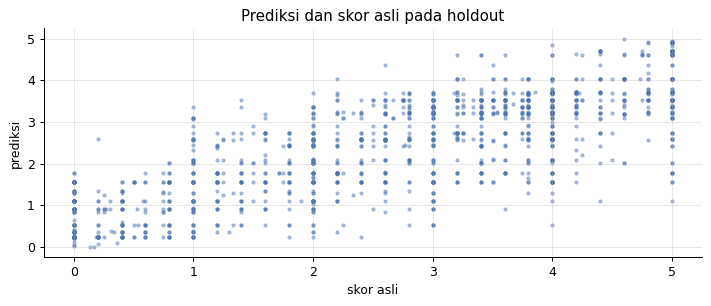

In [18]:
fig, ax = plt.subplots()
ax.scatter(y_holdout, hold_final, s=6, alpha=0.4, color="#4C72B0")
ax.set(title="Prediksi dan skor asli pada holdout", xlabel="skor asli", ylabel="prediksi")
plt.tight_layout()
plt.show()

**Salah paling jauh.**

In [19]:
errors = test.assign(pred=hold_final.round(2), selisih=np.abs(hold_final - y_holdout).round(2))
errors.sort_values("selisih", ascending=False)[["a", "b", "score", "pred"]].head(6)

,a,b,score,pred
823,saya memiliki masalah yang sama dengan anda.,saya baru saja mengalami masalah yang sama.,5.0,1.10
721,saya akan sangat langsung di sini.,"saya akan berterus terang, di sini: anda tidak.",4.0,0.53
724,tidak banyak yang dapat anda lakukan tentang itu.,saya khawatir tidak banyak yang dapat anda lakukan.,5.0,1.56
757,anda melakukannya dengan benar.,"ya, anda mengerti.",5.0,1.56
1340,gempa baru yang kuat mengguncang wilayah pak,"6,8 gempa di wilayah pakistan yang hancur",4.4,1.10
839,saya memiliki masalah yang sama dengan anda.,saya memiliki masalah yang persis sama.,5.0,1.77


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [20]:
pd.DataFrame(
    {"id": test.index, "skor": hold_final.round(3), "parafrase": (hold_blend >= cut).astype(int)}
).to_csv(RESULT_DIR / "submission.csv", index=False)
run_summary(
    "kemiripan",
    len(train),
    {
        "parafrase": paraphrase_scores,
        **{
            r["model"]: {"pearson_oof": r["pearson_oof"], "pearson_holdout": r["pearson_holdout"]}
            for r in results
        },
    },
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=kemiripan mode=penuh n_rows=1500 total_detik=632 gpu=True
{
 "parafrase": {
  "f1_oof": 0.5732,
  "f1_holdout": 0.5745
 },
 "cosine_tfidf": {
  "pearson_oof": 0.6978,
  "pearson_holdout": 0.6111
 },
 "ridge_fitur_kata": {
  "pearson_oof": 0.6963,
  "pearson_holdout": 0.6108
 },
 "biencoder_e5": {
  "pearson_oof": 0.6198,
  "pearson_holdout": 0.6659
 },
 "cross_encoder": {
  "pearson_oof": 0.8319,
  "pearson_holdout": 0.7669
 },
 "gabungan_peringkat": {
  "pearson_oof": 0.7985,
  "pearson_holdout": 0.7762
 },
 "gabungan_plus_kalibrasi": {
  "pearson_oof": 0.7939,
  "pearson_holdout": 0.7788
 }
}


**Poin untuk presentasi**

- Gabungan peringkat dengan kalibrasi: Pearson holdout 0,7788, sedangkan cosine TF-IDF 0,6111.
- Bi-encoder saja kalah dari cross-encoder (0,6659 dibanding 0,7669). Kalau pasangan terlalu banyak, bi-encoder jauh lebih murah (44 detik dibanding 575 detik).
- Gabungan lebih rendah dari cross-encoder di OOF, tapi lebih tinggi di holdout. Gabungan cenderung lebih tahan saat data bergeser.
- Sumber terlemah: `MSRpar` 0,582 dan `answer-answer` 0,614. F1 parafrase holdout hanya 0,5745.